<a href="https://colab.research.google.com/github/drcrajc/all_cancer_ai/blob/main/ALL_SR_Revision_Resumable_Colab_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ALL microscopy: Scientific Reports revision rerun

**Prepared for Dr. Cyril Robinson Azariah J. — 21 October 2026**

This notebook replaces the incomplete image-split experiments. It does not manufacture revised results or guarantee acceptance. All rankings and response claims must follow the new outputs.

## Start here
1. Upload this notebook to Colab; select a GPU runtime. Run cells in order.
2. The default data location is your original `leukemia_4model_run/data/raw/C-NMC_Leukemia/training_data`. The existing `flattened` folder is never used.
3. Run the audit, inspect its patient-ID examples, and confirm the filename schema against the dataset metadata. Set `PATIENT_ID_SCHEMA_CONFIRMED=True` in configuration and rerun from configuration. A custom `PATIENT_MAP_CSV` can override filename-derived IDs.
4. Keep the same `RUN_ROOT` and configuration on every resume. Completed tasks are skipped; an incomplete epoch is repeated from the last committed epoch. Never run two sessions against the same run folder.
5. Core training is substantial: default **24 tuning + 24 main + 12 out-of-fold runs**. Optional controlled learning curves add 24; optional 5×2cv adds 20. No GPU-time estimate is asserted. Use `MAX_NEW_TASKS_PER_CALL` to limit work per session; the cell will stop when the limit is reached.
6. Run development cells until complete. Only then run the clearly marked final-test cell. After inspecting test results, do not tune the protocol further against that test.

### Resume guarantees and limits
Every completed epoch commits a full `.keras` model (including optimizer), history, early-stopping wait count, learning-rate wait count, best epoch and stage. The commit pointer updates last. Interrupted writes are ignored. At most one epoch's work is lost. Full checkpoints are validated as ZIPs and the state ties to a model SHA-256. Best plus latest checkpoints are retained; all epoch metrics remain. Random seeds are recorded, but bitwise reproducibility across different GPUs/TensorFlow versions is not promised. BatchNorm layers stay frozen during transfer learning.

Version 1.1 resolves exact duplicates and uses linked-ID analysis groups. Do not reuse old models or old splits. Colab must have writable access to your Drive folder and enough free space for the retained models. Checkpointing every epoch adds Drive I/O.


## Version 1.1: exact duplicates and linked patient IDs

The raw audit still requires all 10,661 original images and 73 source patient IDs. It then keeps one image per decoded-pixel hash and logs every excluded copy. When identical images occur under different patient IDs, the notebook forms connected components of ALL linked IDs and keeps each component together for every split, cross-validation fold and bootstrap/permutation analysis. IDs are never merged as a biological claim: `original_patient_id` is retained and `analysis_group_id` records the conservative grouping.

Your reported audit (104 two-file duplicate groups) implies **10,557 unique images**, assuming unchanged files and labels. Actual class and group counts are calculated and exported. All analyses and manuscript sample sizes must use these audited retained counts. Deduplication does not establish provenance or exclude near-duplicates. Inspect `audit/patient_group_membership.csv` and document the grouping as a limitation.

Use the same output root to reuse its hash cache only if no experiment has started (as in your audit failure). If `protocol.json` already exists from the older protocol, use a new `RUN_ROOT`; do not delete a protocol to bypass its guard. Re-run cells in order. The confirmation flag still requires verification of the source patient-ID schema.


In [1]:
# 1. Mount Drive and verify the runtime. No TensorFlow upgrade is forced.
from google.colab import drive
drive.mount('/content/drive')
import sys, subprocess, importlib.util
for package, module in [('scikit-learn','sklearn'),('pandas','pandas'),('pillow','PIL'),('matplotlib','matplotlib'),('scipy','scipy')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', package])
import tensorflow as tf
print('TensorFlow:', tf.__version__, 'GPU:', tf.config.list_physical_devices('GPU'))
assert tf.config.list_physical_devices('GPU'), 'Select Runtime > Change runtime type > GPU.'
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError: pass


Mounted at /content/drive
TensorFlow: 2.21.0 GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# 2. Configuration: preserve these values across resumed sessions.
from pathlib import Path
RAW_TRAIN_ROOT = Path('/content/drive/MyDrive/leukemia_4model_run/data/raw/C-NMC_Leukemia/training_data')
RUN_ROOT = Path('/content/drive/MyDrive/leukemia_SR_revision_v1')
PATIENT_ID_SCHEMA_CONFIRMED = True  # set True AFTER inspecting audit and checking dataset metadata
PATIENT_MAP_CSV = ''  # optional CSV: relative_path,patient_id; relative paths beneath RAW_TRAIN_ROOT
EXPECTED_IMAGES = 10661
EXPECTED_CLASS_COUNTS = {1:7272, 0:3389}  # ALL is positive (1); HEM is negative (0)
EXPECTED_PATIENTS = 73  # TCIA training cohort; verify IDs if count differs
SEEDS = [42, 123, 2026]
MODELS = ['MobileNetV2','Xception','ResNet50','DenseNet121']
STRATEGIES = ['baseline','class_weighted']
TUNING_CONFIGS = [
    {'lr':1e-4, 'unfreeze':'last20'},
    {'lr':1e-5, 'unfreeze':'last20'},
    {'lr':1e-5, 'unfreeze':'last20pct'},
]
IMAGE_SIZE = 224
BATCH_SIZE = 32  # lower BEFORE starting a new run if GPU memory is insufficient
WARMUP_EPOCHS = 5  # frozen pretrained backbone, same in every experiment
MAX_FINETUNE_EPOCHS = 50
MIN_FINETUNE_EPOCHS = 12
EARLY_PATIENCE = 10
LR_PATIENCE = 4
MIN_LR = 1e-7
MIN_DELTA = 1e-4
OOF_FOLDS = 3
BOOTSTRAPS = 2000
PERMUTATIONS = 10000
RUN_LEARNING_CURVES = False  # enable before final-test lock if retaining data-efficiency claims
LEARNING_FRACTIONS = [0.4, 0.7, 1.0]
RUN_5X2CV = False  # optional; DEVELOPMENT patients only, never the locked primary test patients
MAX_NEW_TASKS_PER_CALL = 1000  # lower to e.g. 4 for one session
EXTERNAL_MANIFEST_CSV = ''  # optional CSV: path,label,patient_id,source,site,stain,microscope
EXTERNAL_PROVENANCE_CONFIRMED = False  # independent cohort; compatible ALL/HEM presegmented crops
# Blank external input is explicitly marked UNANSWERED in the coverage report.


In [3]:
# 3. Core utilities and complete dataset audit (CPU/Drive I/O).
import os, re, json, hashlib, shutil, time, platform, gc, zipfile, itertools
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_auc_score, average_precision_score, log_loss, roc_curve)
from sklearn.linear_model import LogisticRegression
from scipy.stats import t as student_t
import matplotlib.pyplot as plt

def now(): return datetime.now(timezone.utc).isoformat()
def digest(obj): return hashlib.sha256(json.dumps(obj,sort_keys=True,default=str).encode()).hexdigest()
def sha_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()
def atomic_json(path,obj):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    with open(tmp,'w') as f: json.dump(obj,f,indent=2,allow_nan=False,default=str)
    os.replace(tmp,path)
def read_json(path): return json.loads(Path(path).read_text())
def atomic_csv(path,df):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp');df.to_csv(tmp,index=False);os.replace(tmp,path)
def pixel_hash(path):
    with Image.open(path) as im:
        im=ImageOps.exif_transpose(im).convert('RGB')
        a=np.asarray(im)
        return hashlib.sha256(str(a.shape).encode()+a.tobytes()).hexdigest(), im.width, im.height

RUN_ROOT.mkdir(parents=True,exist_ok=True)
AUDIT=RUN_ROOT/'audit';AUDIT.mkdir(exist_ok=True)
assert RAW_TRAIN_ROOT.is_dir(), f'Original training_data folder not found: {RAW_TRAIN_ROOT}'
assert all((RAW_TRAIN_ROOT/f'fold_{i}').is_dir() for i in range(3)), 'All three original folds are required.'
patient_map={}
if PATIENT_MAP_CSV:
    pm=pd.read_csv(PATIENT_MAP_CSV,dtype=str)
    assert not pm.relative_path.duplicated().any()
    patient_map=dict(zip(pm.relative_path,pm.patient_id))
cache_path=AUDIT/'hash_cache.json'
cache=read_json(cache_path) if cache_path.exists() else {}
rows=[];errors=[]
paths=sorted(p for p in RAW_TRAIN_ROOT.rglob('*') if p.suffix.lower() in {'.bmp','.png','.jpg','.jpeg','.tif','.tiff'})
for i,p in enumerate(paths):
    rel=p.relative_to(RAW_TRAIN_ROOT).as_posix();parts=Path(rel).parts
    if len(parts)<3 or parts[0] not in {'fold_0','fold_1','fold_2'} or parts[1].lower() not in {'all','hem'}:
        errors.append({'path':rel,'error':'Unexpected training directory layout'});continue
    label=1 if parts[1].lower()=='all' else 0
    m=re.search(r'UID_([^_]+)_',p.name,re.I)
    pid=patient_map.get(rel, m.group(1) if m else '')
    if not pid: errors.append({'path':rel,'error':'Missing patient ID'});continue
    # Do not add fold or image index to the patient ID: that could hide patient overlap.
    st=p.stat();stamp=[st.st_size,st.st_mtime_ns]
    try:
        entry=cache.get(rel)
        if not entry or entry['stamp']!=stamp:
            h,w,he=pixel_hash(p);entry={'stamp':stamp,'sha256_pixels':h,'width':w,'height':he};cache[rel]=entry
        rows.append({'relative_path':rel,'path':str(p),'patient_id':str(pid),'label':label,
                     'class_name':'ALL' if label else 'HEM','original_fold':parts[0],**{k:entry[k] for k in ['sha256_pixels','width','height']}})
    except Exception as e: errors.append({'path':rel,'error':str(e)})
    if (i+1)%250==0: atomic_json(cache_path,cache);print('Audited',i+1,'/',len(paths))
atomic_json(cache_path,cache)
manifest=pd.DataFrame(rows)
atomic_csv(AUDIT/'raw_manifest.csv',manifest);atomic_json(AUDIT/'read_errors.json',errors)
assert not errors, f'{len(errors)} unreadable/unmapped images; inspect audit/read_errors.json.'
counts={int(k):int(v) for k,v in manifest.label.value_counts().items()}
summary={'images':len(manifest),'class_counts':counts,'patients':manifest.patient_id.nunique(),
         'fold_counts':manifest.groupby(['original_fold','class_name']).size().to_dict().__str__(),
         'dataset_root':str(RAW_TRAIN_ROOT),'time':now()}
atomic_json(AUDIT/'dataset_summary.json',summary)
print(manifest.groupby(['original_fold','class_name']).size())
print('Patients:',manifest.patient_id.nunique(),'Class counts:',counts)
print(manifest[['relative_path','patient_id','class_name']].head(12).to_string(index=False))
assert len(manifest)==EXPECTED_IMAGES and counts==EXPECTED_CLASS_COUNTS, 'Incomplete/unexpected dataset. Repair ORIGINAL files; do not lower expected counts to bypass this audit.'
assert manifest.patient_id.nunique()==EXPECTED_PATIENTS, 'Patient count differs from expected training cohort. Verify schema/metadata; do not blindly change the number.'
assert manifest.groupby('patient_id').label.nunique().max()==1,'A patient maps to multiple classes; verify metadata.'
assert manifest.groupby('patient_id').original_fold.nunique().max()==1,'UID crosses original folds; verify patient-ID mapping.'
dups=manifest[manifest.sha256_pixels.duplicated(False)].sort_values('sha256_pixels')
atomic_csv(AUDIT/'exact_pixel_duplicates.csv',dups)
def resolve_exact_duplicates(raw):
    """Deduplicate pixels and conservatively group all linked source patient IDs."""
    raw=raw.copy();raw['original_patient_id']=raw.patient_id.astype(str)
    duplicated=raw[raw.sha256_pixels.duplicated(False)].copy()
    if not duplicated.empty:
        conflicts=duplicated.groupby('sha256_pixels').label.nunique()
        assert not (conflicts>1).any(), 'Identical pixels have conflicting labels; resolve provenance before training.'
    parents={p:p for p in sorted(raw.original_patient_id.unique())}
    def find(p):
        while parents[p]!=p:
            parents[p]=parents[parents[p]];p=parents[p]
        return p
    def union(a,b):
        a,b=find(a),find(b)
        if a!=b: parents[max(a,b)]=min(a,b)
    for _,g in duplicated.groupby('sha256_pixels'):
        ids=sorted(g.original_patient_id.unique())
        for other in ids[1:]: union(ids[0],other)
    components={}
    for pid in parents: components.setdefault(find(pid),[]).append(pid)
    mapping={pid:'LG_'+root for root,members in components.items() for pid in members}
    raw['analysis_group_id']=raw.original_patient_id.map(mapping)
    # Existing pipeline uses patient_id as its split/resampling key. Preserve source IDs separately.
    raw['patient_id']=raw.analysis_group_id
    assert raw.groupby('analysis_group_id').label.nunique().max()==1, 'Linked group crosses classes; investigate.'
    membership=pd.DataFrame([{'original_patient_id':pid,'analysis_group_id':mapping[pid]}
                             for pid in sorted(mapping)])
    ordered=raw.sort_values('relative_path').copy()
    retained=ordered.drop_duplicates('sha256_pixels',keep='first').copy()
    removed=ordered[ordered.sha256_pixels.duplicated(keep='first')].copy()
    retained_path=retained.set_index('sha256_pixels').relative_path.to_dict()
    removed['retained_relative_path']=removed.sha256_pixels.map(retained_path)
    assert not retained.sha256_pixels.duplicated().any()
    summary={'raw_images':len(raw),'retained_unique_images':len(retained),'excluded_extra_copies':len(removed),
        'original_patient_ids':len(parents),'analysis_groups':len(components),
        'linked_groups':{mapping[root]:members for root,members in components.items() if len(members)>1},
        'retained_class_counts':{str(k):int(v) for k,v in retained.label.value_counts().items()},
        'policy':'Keep lexicographically first relative path per pixel hash; group all source patient IDs linked by duplicates before splitting and cluster resampling. Original images are never deleted.',
        'interpretation':'Linked IDs are conservative analysis groups, not asserted to be the same biological patient.'}
    return retained,membership,removed,summary

manifest,membership,excluded,duplicate_policy=resolve_exact_duplicates(manifest)
atomic_csv(AUDIT/'patient_group_membership.csv',membership)
atomic_csv(AUDIT/'excluded_duplicate_copies.csv',excluded)
atomic_csv(AUDIT/'manifest.csv',manifest)
atomic_json(AUDIT/'duplicate_resolution.json',duplicate_policy)
print('Duplicate handling:',json.dumps(duplicate_policy,indent=2))
print('All later split/resampling patient_id keys are analysis-group IDs; original_patient_id is preserved.')

# This catches exact duplicates, not every near-duplicate or stain/acquisition confound.
MANIFEST_HASH=digest(manifest[['relative_path','patient_id','original_patient_id','label','sha256_pixels']].to_dict('records'))
print('Audit complete. Inspect UID examples; set PATIENT_ID_SCHEMA_CONFIRMED=True only after metadata verification.')


Audited 250 / 10661
Audited 500 / 10661
Audited 750 / 10661
Audited 1000 / 10661
Audited 1250 / 10661
Audited 1500 / 10661
Audited 1750 / 10661
Audited 2000 / 10661
Audited 2250 / 10661
Audited 2500 / 10661
Audited 2750 / 10661
Audited 3000 / 10661
Audited 3250 / 10661
Audited 3500 / 10661
Audited 3750 / 10661
Audited 4000 / 10661
Audited 4250 / 10661
Audited 4500 / 10661
Audited 4750 / 10661
Audited 5000 / 10661
Audited 5250 / 10661
Audited 5500 / 10661
Audited 5750 / 10661
Audited 6000 / 10661
Audited 6250 / 10661
Audited 6500 / 10661
Audited 6750 / 10661
Audited 7000 / 10661
Audited 7250 / 10661
Audited 7500 / 10661
Audited 7750 / 10661
Audited 8000 / 10661
Audited 8250 / 10661
Audited 8500 / 10661
Audited 8750 / 10661
Audited 9000 / 10661
Audited 9250 / 10661
Audited 9500 / 10661
Audited 9750 / 10661
Audited 10000 / 10661
Audited 10250 / 10661
Audited 10500 / 10661
original_fold  class_name
fold_0         ALL           2397
               HEM           1130
fold_1         ALL      

In [4]:
# 4. Validate protocol and restore patient-disjoint primary split.

import json
import platform
import itertools
from sklearn.model_selection import train_test_split
from IPython.display import display

# Required variables and functions must come from Cells 1–3.
required_names = [
    "PATIENT_ID_SCHEMA_CONFIRMED",
    "RUN_ROOT",
    "MANIFEST_HASH",
    "manifest",
    "tf",
    "digest",
    "read_json",
    "atomic_json",
    "atomic_csv",
    "now",
]

missing_names = [
    name for name in required_names
    if name not in globals()
]

assert not missing_names, (
    f"Missing setup variables: {missing_names}. "
    "Run Cells 1, 2 and 3 first."
)

assert PATIENT_ID_SCHEMA_CONFIRMED, (
    "Verify the source patient-ID schema, set "
    "PATIENT_ID_SCHEMA_CONFIRMED = True in Cell 2, "
    "then rerun Cell 2."
)

# ------------------------------------------------------------
# A. Build the current configuration
# ------------------------------------------------------------

config_fields = [
    "SEEDS",
    "MODELS",
    "STRATEGIES",
    "TUNING_CONFIGS",
    "IMAGE_SIZE",
    "BATCH_SIZE",
    "WARMUP_EPOCHS",
    "MAX_FINETUNE_EPOCHS",
    "MIN_FINETUNE_EPOCHS",
    "EARLY_PATIENCE",
    "LR_PATIENCE",
    "MIN_LR",
    "MIN_DELTA",
    "OOF_FOLDS",
    "BOOTSTRAPS",
    "PERMUTATIONS",
    "LEARNING_FRACTIONS",
]

missing_settings = [
    name for name in config_fields
    if name not in globals()
]

assert not missing_settings, (
    f"Missing configuration settings: {missing_settings}. "
    "Rerun Cell 2."
)

CURRENT_CONFIG = {
    name: globals()[name]
    for name in config_fields
}

CURRENT_CONFIG.update(
    manifest_hash=MANIFEST_HASH,
    protocol_version="SR-v1.1-duplicate-linked-groups",
    tensorflow=tf.__version__,
    python=platform.python_version(),
    label_mapping={"HEM": 0, "ALL": 1},
)

CORE_CONFIG = CURRENT_CONFIG.copy()
CONFIG_HASH = digest(CORE_CONFIG)

RUN_ROOT.mkdir(parents=True, exist_ok=True)
protocol_path = RUN_ROOT / "protocol.json"

# ------------------------------------------------------------
# B. Validate the saved protocol
#    Permit only a Python patch-version change.
# ------------------------------------------------------------

if protocol_path.exists():
    saved_protocol = read_json(protocol_path)
    previous_config = saved_protocol["config"]

    assert digest(previous_config) == saved_protocol["hash"], (
        "The saved protocol hash is invalid. "
        "Do not overwrite protocol.json."
    )

    changed_fields = [
        key
        for key in sorted(
            set(previous_config) | set(CURRENT_CONFIG)
        )
        if json.dumps(previous_config.get(key), sort_keys=True)
        != json.dumps(CURRENT_CONFIG.get(key), sort_keys=True)
    ]

    if changed_fields:
        print("Detected protocol differences:")

        for key in changed_fields:
            print(f"\n{key}")
            print("  Saved:  ", previous_config.get(key))
            print("  Current:", CURRENT_CONFIG.get(key))

        old_python = str(previous_config.get("python", ""))
        new_python = str(CURRENT_CONFIG.get("python", ""))

        old_parts = old_python.split(".")
        new_parts = new_python.split(".")

        python_patch_only = (
            changed_fields == ["python"]
            and len(old_parts) == 3
            and len(new_parts) == 3
            and all(
                part.isdigit()
                for part in old_parts + new_parts
            )
            and old_parts[:2] == new_parts[:2]
        )

        assert python_patch_only, (
            f"Changes other than a Python patch version were "
            f"detected: {changed_fields}. "
            "Restore the original settings before resuming. "
            "Do not delete the protocol or checkpoints."
        )

        # Record the observed environment change.
        # The original protocol remains unchanged.
        log_path = RUN_ROOT / "runtime_resume_events.json"
        events = (
            read_json(log_path)
            if log_path.exists()
            else []
        )

        event_details = {
            "saved_python": old_python,
            "current_python": new_python,
            "protocol_hash": saved_protocol["hash"],
            "reason": "Resume after Python patch-version change",
        }

        already_logged = any(
            all(
                event.get(key) == value
                for key, value in event_details.items()
            )
            for event in events
        )

        if not already_logged:
            events.append({
                "time": now(),
                **event_details,
            })
            atomic_json(log_path, events)

        print(
            f"\nPython patch-version change recorded: "
            f"{old_python} -> {new_python}"
        )

    # Preserve the original hash used by saved task checkpoints.
    CORE_CONFIG = previous_config.copy()
    CONFIG_HASH = saved_protocol["hash"]

    print("\nSaved protocol preserved.")
    print("Original checkpoint identity preserved.")

else:
    atomic_json(
        protocol_path,
        {
            "hash": CONFIG_HASH,
            "config": CORE_CONFIG,
            "created": now(),
        },
    )

    print("New protocol saved.")

# ------------------------------------------------------------
# C. Check the audited manifest
#
# patient_id is the analysis-group key created in Cell 3.
# original_patient_id preserves the source patient identifier.
# ------------------------------------------------------------

required_columns = {
    "relative_path",
    "path",
    "patient_id",
    "original_patient_id",
    "analysis_group_id",
    "label",
    "class_name",
    "sha256_pixels",
}

assert required_columns.issubset(manifest.columns), (
    "The audited manifest is missing required columns. "
    "Rerun the updated Cell 3."
)

assert manifest[list(required_columns)].notna().all().all(), (
    "Missing values exist in required manifest columns."
)

assert not manifest.relative_path.duplicated().any(), (
    "Repeated image paths exist in the audited manifest."
)

assert not manifest.sha256_pixels.duplicated().any(), (
    "Exact duplicate images remain. "
    "Rerun duplicate resolution in Cell 3."
)

assert (
    manifest.patient_id.astype(str)
    == manifest.analysis_group_id.astype(str)
).all(), "patient_id must match the analysis-group key."

assert (
    manifest.groupby("patient_id").label.nunique().max() == 1
), "An analysis group contains conflicting class labels."

PATIENTS = (
    manifest[["patient_id", "label"]]
    .drop_duplicates()
    .sort_values("patient_id")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# D. Split and independence helpers
# ------------------------------------------------------------

def patient_split(df, fraction, seed):
    groups = (
        df[["patient_id", "label"]]
        .drop_duplicates()
        .sort_values("patient_id")
    )

    assert (
        groups.groupby("patient_id").label.nunique().max() == 1
    ), "An analysis group contains conflicting labels."

    first_ids, second_ids = train_test_split(
        groups.patient_id.to_numpy(),
        test_size=fraction,
        stratify=groups.label.to_numpy(),
        random_state=seed,
    )

    return (
        df[df.patient_id.isin(first_ids)].copy(),
        df[df.patient_id.isin(second_ids)].copy(),
    )


def assert_disjoint(*frames):
    for first, second in itertools.combinations(frames, 2):
        assert set(first.patient_id).isdisjoint(
            second.patient_id
        ), "Analysis-group overlap between partitions."

        assert set(first.sha256_pixels).isdisjoint(
            second.sha256_pixels
        ), "Identical image pixels occur in different partitions."

        if (
            "original_patient_id" in first.columns
            and "original_patient_id" in second.columns
        ):
            assert set(first.original_patient_id).isdisjoint(
                second.original_patient_id
            ), "Original patient-ID overlap between partitions."

    assert all(
        set(frame.label) == {0, 1}
        for frame in frames
    ), "Each partition must contain both classes."

# ------------------------------------------------------------
# E. Restore the saved split, or create it once
# ------------------------------------------------------------

split_path = RUN_ROOT / "splits" / "primary.json"

if split_path.exists():
    sp = read_json(split_path)

    assert sp["manifest_hash"] == MANIFEST_HASH, (
        "The dataset fingerprint differs from the saved split. "
        "Do not overwrite the saved split."
    )

    print("Loaded existing primary split.")

else:
    dev, test = patient_split(
        manifest,
        fraction=0.15,
        seed=42,
    )

    train, val = patient_split(
        dev,
        fraction=0.15 / 0.85,
        seed=43,
    )

    sp = {
        "manifest_hash": MANIFEST_HASH,
        "train": sorted(train.patient_id.unique()),
        "validation": sorted(val.patient_id.unique()),
        "test": sorted(test.patient_id.unique()),
    }

    atomic_json(split_path, sp)
    print("Created and saved the primary split.")

split_names = ["train", "validation", "test"]

group_sets = {
    name: set(sp[name])
    for name in split_names
}

for name in split_names:
    assert len(sp[name]) == len(group_sets[name]), (
        f"Repeated analysis-group IDs in {name}."
    )

for first, second in itertools.combinations(split_names, 2):
    assert group_sets[first].isdisjoint(group_sets[second]), (
        f"Saved group overlap: {first} and {second}."
    )

assert (
    set().union(*group_sets.values())
    == set(manifest.patient_id)
), "Saved split does not exactly cover the analysis groups."

TRAIN = manifest[
    manifest.patient_id.isin(sp["train"])
].copy()

VAL = manifest[
    manifest.patient_id.isin(sp["validation"])
].copy()

TEST = manifest[
    manifest.patient_id.isin(sp["test"])
].copy()

DEV = manifest[
    ~manifest.patient_id.isin(sp["test"])
].copy()

assert_disjoint(TRAIN, VAL, TEST)

assert (
    len(TRAIN) + len(VAL) + len(TEST)
    == len(manifest)
), "Partition counts do not cover all usable images."

# ------------------------------------------------------------
# F. Save partition assignments and counts
# ------------------------------------------------------------

partition_map = {
    group_id: partition
    for partition in split_names
    for group_id in sp[partition]
}

manifest["partition"] = (
    manifest.patient_id.map(partition_map)
)

assert manifest.partition.notna().all(), (
    "Some images have no partition assignment."
)

atomic_csv(
    RUN_ROOT / "splits" / "primary_manifest.csv",
    manifest,
)

partition_counts = (
    manifest.groupby(["partition", "class_name"])
    .agg(
        images=("path", "size"),
        analysis_groups=("analysis_group_id", "nunique"),
        original_patient_ids=("original_patient_id", "nunique"),
    )
    .reset_index()
)

atomic_csv(
    RUN_ROOT / "splits" / "partition_counts.csv",
    partition_counts,
)

display(partition_counts)

print(f"\nTraining images:   {len(TRAIN):,}")
print(f"Validation images: {len(VAL):,}")
print(f"Test images:       {len(TEST):,}")
print(f"Total images:      {len(manifest):,}")

print("\nCell 4 completed successfully.")
print("Next: Cell 5 -> checkpoint smoke test -> Cell 6.")

# Keep the saved split fixed throughout the experiment.

Detected protocol differences:

python
  Saved:   3.13.15
  Current: 3.13.16

Python patch-version change recorded: 3.13.15 -> 3.13.16

Saved protocol preserved.
Original checkpoint identity preserved.
Loaded existing primary split.


,partition,class_name,images,analysis_groups,original_patient_ids
0,test,ALL,1060,7,7
1,test,HEM,507,3,3
2,train,ALL,5036,30,33
3,train,HEM,2651,16,20
4,validation,ALL,1084,7,7
5,validation,HEM,219,3,3



Training images:   7,687
Validation images: 1,303
Test images:       1,567
Total images:      10,557

Cell 4 completed successfully.
Next: Cell 5 -> checkpoint smoke test -> Cell 6.


In [8]:
# 5. Model, pipeline and transaction-safe epoch checkpoints.
from tensorflow.keras import layers

@tf.keras.utils.register_keras_serializable(package='ALLRevision')
class BackbonePreprocess(layers.Layer):
    def __init__(self, model_name, **kwargs):
        super().__init__(**kwargs);self.model_name=model_name
    def call(self,x):
        x=tf.cast(x,tf.float32)
        if self.model_name in ['MobileNetV2','Xception']: return x/127.5-1.
        if self.model_name=='DenseNet121':
            return (x/255.-tf.constant([.485,.456,.406],tf.float32))/tf.constant([.229,.224,.225],tf.float32)
        return tf.reverse(x,axis=[-1])-tf.constant([103.939,116.779,123.68],tf.float32)
    def get_config(self): return {**super().get_config(),'model_name':self.model_name}

BACKBONES={n:getattr(tf.keras.applications,n) for n in MODELS}
def build_model(name,seed):
    tf.keras.utils.set_random_seed(seed)
    inp=layers.Input((IMAGE_SIZE,IMAGE_SIZE,3),name='image')
    x=layers.RandomFlip('horizontal_and_vertical',seed=seed+1)(inp)
    x=layers.RandomRotation(.0416667,seed=seed+2)(x)
    x=layers.RandomZoom(.1,seed=seed+3)(x)
    x=layers.RandomTranslation(.05,.05,seed=seed+4)(x)
    x=BackbonePreprocess(name)(x)
    base=BACKBONES[name](include_top=False,weights='imagenet',input_shape=(IMAGE_SIZE,IMAGE_SIZE,3))
    base._name='backbone'
    base.trainable=False
    # training=False freezes backbone BN statistics while allowing gradients through unfrozen weights.
    x=base(x,training=False)
    x=layers.GlobalAveragePooling2D()(x)
    x=layers.BatchNormalization()(x)
    x=layers.Dropout(.3,seed=seed+5)(x)
    x=layers.Dense(128,activation='relu')(x)
    x=layers.Dropout(.2,seed=seed+6)(x)
    out=layers.Dense(2,activation='softmax',name='probabilities')(x)
    return tf.keras.Model(inp,out,name=name+'_revision')

def backbone(model):
    return next(l for l in model.layers if isinstance(l,tf.keras.Model))
def configure_phase(model,phase,cfg):
    b=backbone(model);b.trainable=(phase=='finetune')
    if phase=='finetune':
        n=20 if cfg['unfreeze']=='last20' else max(1,int(len(b.layers)*.2))
        for i,l in enumerate(b.layers):
            l.trainable=i>=len(b.layers)-n and not isinstance(l,layers.BatchNormalization)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3 if phase=='warmup' else cfg['lr']),
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=.05),
        metrics=[tf.keras.metrics.CategoricalAccuracy(name='accuracy')])

def dataset(df,training=False,seed=42):
    # PIL explicitly supports BMP and TIFF; tf.decode_image does not support TIFF.
    df=df.reset_index(drop=True)
    def load_py(path):
        path=path.numpy().decode()
        with Image.open(path) as im:
            im=ImageOps.exif_transpose(im).convert('RGB').resize((IMAGE_SIZE,IMAGE_SIZE),Image.Resampling.BILINEAR)
            return np.asarray(im,dtype=np.float32)
    def load(path,y):
        x=tf.py_function(load_py,[path],tf.float32);x.set_shape((IMAGE_SIZE,IMAGE_SIZE,3))
        return x,tf.one_hot(y,2)
    ds=tf.data.Dataset.from_tensor_slices((df.path.astype(str).to_numpy(),df.label.to_numpy(np.int32)))
    if training: ds=ds.shuffle(len(df),seed=seed,reshuffle_each_iteration=False)
    opt=tf.data.Options();opt.experimental_deterministic=True
    return ds.with_options(opt).map(load,num_parallel_calls=4).batch(BATCH_SIZE).prefetch(2)

def task_folder(key): return RUN_ROOT/'tasks'/key

def load_committed(folder):
    candidates=[]
    pointer=folder/'latest.json'
    if pointer.exists(): candidates.append(read_json(pointer)['directory'])
    candidates += [p.name for p in sorted(folder.glob('epoch_*'),reverse=True) if p.is_dir()]
    for name in dict.fromkeys(candidates):
        d=folder/name
        try:
            s=read_json(d/'state.json')
            assert s['model_sha256']==sha_file(d/'model.keras')
            assert zipfile.is_zipfile(d/'model.keras')
            return d,s
        except Exception: continue
    return None,None

def commit(folder,model,state):
    d=folder/f"epoch_{state['global_epoch']:04d}"
    if d.exists(): shutil.rmtree(d)  # only an orphan/uncommitted generation can share this epoch
    d.mkdir(parents=True)
    tmp=d/'writing.keras';model.save(tmp);os.replace(tmp,d/'model.keras')
    assert zipfile.is_zipfile(d/'model.keras')
    state['model_sha256']=sha_file(d/'model.keras')
    atomic_json(d/'state.json',state)
    atomic_json(folder/'latest.json',{'directory':d.name,'epoch':state['global_epoch']})
    atomic_csv(folder/'history.csv',pd.DataFrame(state['history']))
    keep={d.name,state.get('best_directory')}
    for old in folder.glob('epoch_*'):
        if old.is_dir() and old.name not in keep: shutil.rmtree(old)
    return d

NEW_TASKS=0

def run_task(key,name,tr,va,cfg,strategy,seed,_interrupt_after_epoch=None):
    global NEW_TASKS
    assert_disjoint(tr,va)
    folder=task_folder(key);folder.mkdir(parents=True,exist_ok=True)
    task_spec={'protocol':CONFIG_HASH,'model':name,'cfg':cfg,'strategy':strategy,'seed':seed,
        'train':sorted(tr.relative_path.tolist()),'validation':sorted(va.relative_path.tolist())}
    th=digest(task_spec);specpath=folder/'task_spec.json'
    if specpath.exists(): assert read_json(specpath)['hash']==th, f'Task changed: {key}'
    else: atomic_json(specpath,{'hash':th,'spec':task_spec})
    done=folder/'completed.json'
    if done.exists():
        result=read_json(done);assert result['task_hash']==th
        print('SKIP',key);return result
    assert not (RUN_ROOT/'FINAL_TEST_LOCK.json').exists(),'Final-test lock exists; development changes are disabled.'
    if NEW_TASKS>=MAX_NEW_TASKS_PER_CALL: raise RuntimeError('Session task limit reached. Rerun this cell in the next session.')
    NEW_TASKS+=1
    last,state=load_committed(folder)
    tf.keras.backend.clear_session();gc.collect()
    if state is None:
        model=build_model(name,seed);configure_phase(model,'warmup',cfg)
        state={'task_hash':th,'phase':'warmup','phase_epoch':0,'global_epoch':0,'wait':0,'lr_wait':0,
               'best_loss':None,'best_epoch':None,'best_directory':None,'best_reference':None,'history':[]}
    else:
        assert state['task_hash']==th
        model=tf.keras.models.load_model(last/'model.keras')
        print('RESUME',key,'after epoch',state['global_epoch'],'phase',state['phase'])
    counts=tr.label.value_counts()
    cw={i:len(tr)/(2*int(counts[i])) for i in [0,1]} if strategy=='class_weighted' else None
    while True:
        if state['phase']=='warmup' and state['phase_epoch']>=WARMUP_EPOCHS:
            # Begin fine-tuning from the best validation-loss warmup model, not the last one.
            model=tf.keras.models.load_model(folder/state['best_directory']/'model.keras')
            configure_phase(model,'finetune',cfg)
            state.update(phase='finetune',phase_epoch=0,wait=0,lr_wait=0)
        if state['phase']=='finetune' and (state['phase_epoch']>=MAX_FINETUNE_EPOCHS or
           (state['phase_epoch']>=MIN_FINETUNE_EPOCHS and state['wait']>=EARLY_PATIENCE)):
            break
        epoch=state['global_epoch']+1
        tf.keras.utils.set_random_seed(seed+epoch)
        t0=time.time()
        logs=model.fit(dataset(tr,True,seed+epoch),validation_data=dataset(va),epochs=1,
                       class_weight=cw,verbose=1).history
        vl=float(logs['val_loss'][0]);assert np.isfinite(vl), 'Non-finite loss; inspect model/data.'
        state['global_epoch']=epoch;state['phase_epoch']+=1
        best=state['best_loss']
        if best is None or vl<best:
            state.update(best_loss=vl,best_epoch=epoch,best_directory=f'epoch_{epoch:04d}')
        # Separate min_delta improvement reference avoids counting tiny changes as convergence.
        ref=state['best_reference']
        improved=ref is None or vl<ref-MIN_DELTA
        if improved: state.update(best_reference=vl,wait=0,lr_wait=0)
        else:
            state['wait']+=1;state['lr_wait']+=1
        lr=float(tf.keras.backend.get_value(model.optimizer.learning_rate))
        if state['phase']=='finetune' and state['lr_wait']>=LR_PATIENCE:
            model.optimizer.learning_rate.assign(max(MIN_LR,lr*.5));state['lr_wait']=0
        row={'epoch':epoch,'phase':state['phase'],'phase_epoch':state['phase_epoch'],
             **{k:float(v[0]) for k,v in logs.items()},'lr_used':lr,'seconds':time.time()-t0,
             'early_wait':state['wait'],'lr_wait':state['lr_wait']}
        state['history'].append(row)
        last=commit(folder,model,state)
        print(key,'committed epoch',epoch,'best',state['best_epoch'])
        if _interrupt_after_epoch is not None and epoch==_interrupt_after_epoch:
            raise InterruptedError('Intentional smoke-test interruption after committed epoch.')
    bestpath=folder/state['best_directory']/'model.keras'
    bestmodel=tf.keras.models.load_model(bestpath)
    pred=prediction_frame(bestmodel,va)
    atomic_csv(folder/'validation_predictions.csv',pred)
    result={'task_hash':th,'key':key,'model':name,'strategy':strategy,'seed':seed,'cfg':cfg,
            'best_model':str(bestpath),'best_epoch':state['best_epoch'],'stopping_epoch':state['global_epoch'],
            'fine_tune_epochs':state['phase_epoch'],'hit_epoch_cap':state['phase_epoch']>=MAX_FINETUNE_EPOCHS,
            'validation_metrics':metrics(pred),'completed':now()}
    atomic_json(done,result)
    del model,bestmodel;tf.keras.backend.clear_session();gc.collect()
    return result

def prediction_frame(model,df):
    df=df.reset_index(drop=True)
    p=model.predict(dataset(df),verbose=0)[:,1]
    return pd.DataFrame({'relative_path':df.relative_path,'patient_id':df.patient_id.astype(str),
        'label':df.label,'p_all':p,'prediction':(p>=.5).astype(int),
        'original_patient_id':df.original_patient_id.astype(str) if 'original_patient_id' in df else df.patient_id.astype(str)})

def metrics(pred):
    y=pred.label.to_numpy(int);p=pred.p_all.to_numpy(float);q=(p>=.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,q,labels=[0,1]).ravel()
    pr,re,f1,sup=precision_recall_fscore_support(y,q,labels=[0,1],zero_division=0)
    patient_acc=pd.DataFrame({'g':pred.patient_id.to_numpy(),'v':(y==q).astype(float)}).groupby('g').v.mean().mean()
    return {'accuracy':float(accuracy_score(y,q)),'balanced_accuracy':float(balanced_accuracy_score(y,q)),
      'macro_precision':float(pr.mean()),'macro_recall':float(re.mean()),'macro_f1':float(f1.mean()),
      'sensitivity_all':float(tp/(tp+fn)),'specificity_hem':float(tn/(tn+fp)),
      'roc_auc':float(roc_auc_score(y,p)),'pr_auc_all':float(average_precision_score(y,p)),
      'log_loss':float(log_loss(y,np.column_stack([1-p,p]),labels=[0,1])),
      'patient_mean_cell_accuracy':float(patient_acc),'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp),
      'n_images':len(pred),'n_patients':int(pred.original_patient_id.nunique()) if 'original_patient_id' in pred else int(pred.patient_id.nunique()),
      'n_analysis_groups':int(pred.patient_id.nunique())}

def load_pred(path): return pd.read_csv(path,dtype={'patient_id':str,'relative_path':str})

def require_complete(results,expected):
    assert len(results)==expected,'Development is incomplete; rerun the preceding task cell.'


In [9]:
# Checkpoint smoke test: a tiny synthetic CNN; intentionally interrupt, then resume.
# Does NOT train/evaluate any leukemia model or consume primary test images.
SMOKE_ROOT = RUN_ROOT/'checkpoint_smoke_test'
if not (SMOKE_ROOT/'passed.json').exists():
    # A failed synthetic test is safe to restart; real experiment folders are never deleted.
    if SMOKE_ROOT.exists(): shutil.rmtree(SMOKE_ROOT)
    saved={k:globals()[k] for k in ['RUN_ROOT','CONFIG_HASH','WARMUP_EPOCHS','MAX_FINETUNE_EPOCHS',
           'MIN_FINETUNE_EPOCHS','EARLY_PATIENCE','LR_PATIENCE','NEW_TASKS','build_model']}
    try:
        RUN_ROOT=SMOKE_ROOT;RUN_ROOT.mkdir(parents=True,exist_ok=True)
        CONFIG_HASH='synthetic-smoke-v1';WARMUP_EPOCHS=1;MAX_FINETUNE_EPOCHS=2
        MIN_FINETUNE_EPOCHS=2;EARLY_PATIENCE=1;LR_PATIENCE=1;NEW_TASKS=0
        rows=[];rng=np.random.default_rng(998)
        for i in range(8):
            path=RUN_ROOT/f'synthetic_{i}.png'
            arr=rng.integers(0,256,(32,32,3),dtype=np.uint8);Image.fromarray(arr).save(path)
            rows.append({'path':str(path),'relative_path':path.name,'patient_id':str(i),'label':i%2,
                         'sha256_pixels':pixel_hash(path)[0]})
        toy=pd.DataFrame(rows);tr=toy.iloc[:4].copy();va=toy.iloc[4:].copy()
        def build_model(name,seed):
            tf.keras.utils.set_random_seed(seed)
            bi=layers.Input((IMAGE_SIZE,IMAGE_SIZE,3));bx=layers.Rescaling(1./255)(bi)
            bx=layers.Conv2D(2,3,strides=16,activation='relu')(bx)
            base=tf.keras.Model(bi,bx,name='tiny_backbone');base.trainable=False
            inp=layers.Input((IMAGE_SIZE,IMAGE_SIZE,3));x=base(inp,training=False)
            x=layers.GlobalAveragePooling2D()(x);out=layers.Dense(2,activation='softmax')(x)
            return tf.keras.Model(inp,out)
        cfg={'lr':1e-4,'unfreeze':'last20'}
        try: run_task('tiny','Smoke',tr,va,cfg,'baseline',42,_interrupt_after_epoch=1)
        except InterruptedError: pass
        folder=task_folder('tiny');last,state=load_committed(folder)
        assert state['global_epoch']==1
        restored=tf.keras.models.load_model(last/'model.keras')
        assert int(restored.optimizer.iterations.numpy())>0,'Optimizer state not restored.'
        result=run_task('tiny','Smoke',tr,va,cfg,'baseline',42)
        assert result['stopping_epoch']==3
        hist=pd.read_csv(folder/'history.csv');assert hist.epoch.tolist()==[1,2,3]
        assert run_task('tiny','Smoke',tr,va,cfg,'baseline',42)==result,'Completed task was not reused.'
        atomic_json(SMOKE_ROOT/'passed.json',{'passed':True,'time':now(),
            'checks':['whole-model optimizer restore','intentional interruption','resume without duplicate epochs','completed-task skip']})
        print('Checkpoint smoke test PASSED.')
    finally:
        for k,v in saved.items(): globals()[k]=v
        tf.keras.backend.clear_session();gc.collect()
else: print('Checkpoint smoke test previously passed:',SMOKE_ROOT/'passed.json')


Checkpoint smoke test previously passed: /content/drive/MyDrive/leukemia_SR_revision_v1/checkpoint_smoke_test/passed.json


## Development experiments — the test set is not evaluated here

Tuning compares three prespecified configurations for **each architecture and imbalance strategy**, using the same primary validation patients. Selection minimizes unsmoothed validation log-loss from saved probabilities, while checkpoints minimize validation training loss (cross-entropy with label smoothing). Both criteria are reported. Baseline means no class weighting; both arms use the same label smoothing and augmentation. No random oversampling or test threshold optimization is used.

A frozen-backbone warmup is followed by partial fine-tuning. The best checkpoint may remain in warmup if fine-tuning never improves validation loss. A run reaching the epoch cap is flagged; inspect all histories before locking the test and increase budgets only in a new, documented protocol if needed. Early stopping is an operational rule, not proof of mathematical convergence.


In [10]:
# 6. Tune each model/imbalance arm. Rerun this cell until all tasks complete.
NEW_TASKS=0
TUNING=[]
for name in MODELS:
    for strategy in STRATEGIES:
        for i,cfg in enumerate(TUNING_CONFIGS):
            key=f'tune/{name}/{strategy}/config{i}'
            r=run_task(key,name,TRAIN,VAL,cfg,strategy,SEEDS[0]);TUNING.append(r)
require_complete(TUNING,len(MODELS)*len(STRATEGIES)*len(TUNING_CONFIGS))
SELECTED={}
for name in MODELS:
    for strategy in STRATEGIES:
        candidates=[r for r in TUNING if r['model']==name and r['strategy']==strategy]
        SELECTED[name+'__'+strategy]=min(candidates,key=lambda r:r['validation_metrics']['log_loss'])['cfg']
atomic_json(RUN_ROOT/'selected_configs.json',SELECTED)
atomic_csv(RUN_ROOT/'tuning_summary.csv',pd.DataFrame([{**{k:r[k] for k in ['key','model','strategy','seed','best_epoch','stopping_epoch','hit_epoch_cap']},
   **r['cfg'],**r['validation_metrics']} for r in TUNING]))
print('Tuning complete. Selected configurations:',SELECTED)


SKIP tune/MobileNetV2/baseline/config0
RESUME tune/MobileNetV2/baseline/config1 after epoch 2 phase warmup
241/241 ━━━━━━━━━━━━━━━━━━━━ 303s 1s/step - accuracy: 0.8131 - loss: 0.4618 - val_accuracy: 0.8795 - val_loss: 0.4015
tune/MobileNetV2/baseline/config1 committed epoch 3 best 2
241/241 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.8246 - loss: 0.4460 - val_accuracy: 0.8795 - val_loss: 0.3998
tune/MobileNetV2/baseline/config1 committed epoch 4 best 2
241/241 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.8253 - loss: 0.4407 - val_accuracy: 0.8757 - val_loss: 0.4277
tune/MobileNetV2/baseline/config1 committed epoch 5 best 2
241/241 ━━━━━━━━━━━━━━━━━━━━ 19s 39ms/step - accuracy: 0.8153 - loss: 0.4607 - val_accuracy: 0.8833 - val_loss: 0.3998
tune/MobileNetV2/baseline/config1 committed epoch 6 best 2
241/241 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - accuracy: 0.8213 - loss: 0.4420 - val_accuracy: 0.8795 - val_loss: 0.3969
tune/MobileNetV2/baseline/config1 committed epoch 7 best 2
241/241

In [11]:
# 7. Repeat all model/imbalance arms with three random seeds.
NEW_TASKS=0
SELECTED=read_json(RUN_ROOT/'selected_configs.json');MAIN=[]
for name in MODELS:
    for strategy in STRATEGIES:
        for seed in SEEDS:
            MAIN.append(run_task(f'main/{name}/{strategy}/seed{seed}',name,TRAIN,VAL,
                       SELECTED[name+'__'+strategy],strategy,seed))
require_complete(MAIN,len(MODELS)*len(STRATEGIES)*len(SEEDS))
# Ensemble uses one validation-selected arm per architecture, always prespecified seed 42.
# The primary single-model comparison reports BOTH arms and all seeds, not only the winner.
ARM={name:min(STRATEGIES,key=lambda s:np.mean([r['validation_metrics']['log_loss'] for r in MAIN
                          if r['model']==name and r['strategy']==s])) for name in MODELS}
REFERENCE_MODEL=min(MODELS,key=lambda n:np.mean([r['validation_metrics']['log_loss'] for r in MAIN
                                      if r['model']==n and r['strategy']==ARM[n]]))
atomic_json(RUN_ROOT/'ensemble_protocol.json',{'arms':ARM,'reference_model':REFERENCE_MODEL,'seed':SEEDS[0],
 'threshold':.5,'meta_C':1.,'feature':'four ALL probabilities','voting_weights':'OOF balanced accuracy'})
atomic_csv(RUN_ROOT/'main_validation_summary.csv',pd.DataFrame([{**{k:r[k] for k in ['key','model','strategy','seed','best_epoch','stopping_epoch','hit_epoch_cap']},
 **r['validation_metrics']} for r in MAIN]))
print('Selected ensemble arms:',ARM,'Prespecified comparison reference:',REFERENCE_MODEL)


241/241 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.7550 - loss: 0.6119 - val_accuracy: 0.8496 - val_loss: 0.4569
main/MobileNetV2/baseline/seed42 committed epoch 1 best 1
241/241 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.7929 - loss: 0.4945 - val_accuracy: 0.8780 - val_loss: 0.3997
main/MobileNetV2/baseline/seed42 committed epoch 2 best 2
241/241 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.8067 - loss: 0.4632 - val_accuracy: 0.8772 - val_loss: 0.4100
main/MobileNetV2/baseline/seed42 committed epoch 3 best 2
241/241 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.8180 - loss: 0.4545 - val_accuracy: 0.8895 - val_loss: 0.3991
main/MobileNetV2/baseline/seed42 committed epoch 4 best 4
241/241 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.8214 - loss: 0.4450 - val_accuracy: 0.8856 - val_loss: 0.4030
main/MobileNetV2/baseline/seed42 committed epoch 5 best 4
241/241 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - accuracy: 0.8245 - loss: 0.4411 - val_accuracy: 0.8718 - val_loss: 0.4674


In [18]:
# 8. Patient-grouped out-of-fold probabilities for leakage-free stacking.
# OOF held-out patients are never used for a fold's checkpoint selection.
NEW_TASKS=0
EP=read_json(RUN_ROOT/'ensemble_protocol.json');ARM=EP['arms']
pt=TRAIN[['patient_id','label']].drop_duplicates().sort_values('patient_id').reset_index(drop=True)
skf=StratifiedKFold(OOF_FOLDS,shuffle=True,random_state=31415)
OOF=[]
for fold,(ii,jj) in enumerate(skf.split(pt.patient_id,pt.label)):
    pool=TRAIN[TRAIN.patient_id.isin(pt.iloc[ii].patient_id)].copy()
    held=TRAIN[TRAIN.patient_id.isin(pt.iloc[jj].patient_id)].copy()
    inner_tr,inner_va=patient_split(pool,.2,500+fold)
    assert_disjoint(inner_tr,inner_va,held)
    atomic_json(RUN_ROOT/f'splits/oof_fold{fold}.json',{'train':sorted(inner_tr.patient_id.unique()),
        'validation':sorted(inner_va.patient_id.unique()),'held_out':sorted(held.patient_id.unique())})
    merged=held[['relative_path','patient_id','label']].reset_index(drop=True)
    for name in MODELS:
        key=f'oof/{name}/fold{fold}'
        r=run_task(key,name,inner_tr,inner_va,SELECTED[name+'__'+ARM[name]],ARM[name],SEEDS[0])
        dest=task_folder(key)/'oof_predictions.csv'
        if dest.exists(): pred=load_pred(dest)
        else:
            m=tf.keras.models.load_model(r['best_model']);pred=prediction_frame(m,held);atomic_csv(dest,pred)
            del m;tf.keras.backend.clear_session();gc.collect()
        merged=merged.merge(pred[['relative_path','p_all']].rename(columns={'p_all':name}),on='relative_path',validate='one_to_one')
    merged['fold']=fold;OOF.append(merged)
OOF=pd.concat(OOF,ignore_index=True).sort_values('relative_path').reset_index(drop=True)
assert len(OOF)==len(TRAIN) and not OOF.relative_path.duplicated().any()
atomic_csv(RUN_ROOT/'ensemble/oof_probabilities.csv',OOF)
weights=[]
for name in MODELS: weights.append(balanced_accuracy_score(OOF.label,(OOF[name]>=.5).astype(int)))
weights=np.array(weights)/np.sum(weights)
# C and threshold are prespecified; no test-based selection of ensemble type.
meta=LogisticRegression(C=1.,max_iter=3000,random_state=42,class_weight=None)
meta.fit(OOF[MODELS].to_numpy(),OOF.label)
atomic_json(RUN_ROOT/'ensemble/meta.json',{'coef':meta.coef_.tolist(),'intercept':meta.intercept_.tolist(),
    'classes':meta.classes_.tolist(),'features':MODELS,'weights':weights.tolist(),'C':1.,'threshold':.5,
    'oof_hash':sha_file(RUN_ROOT/'ensemble/oof_probabilities.csv')})
print('Ensemble fitted using training-patient OOF predictions only. Weights:',dict(zip(MODELS,weights)))


SKIP oof/MobileNetV2/fold0
SKIP oof/Xception/fold0
SKIP oof/ResNet50/fold0
SKIP oof/DenseNet121/fold0
SKIP oof/MobileNetV2/fold1
SKIP oof/Xception/fold1
SKIP oof/ResNet50/fold1
SKIP oof/DenseNet121/fold1
SKIP oof/MobileNetV2/fold2
SKIP oof/Xception/fold2
SKIP oof/ResNet50/fold2
SKIP oof/DenseNet121/fold2
Ensemble fitted using training-patient OOF predictions only. Weights: {'MobileNetV2': np.float64(0.24605424287805355), 'Xception': np.float64(0.2685508400330724), 'ResNet50': np.float64(0.238284072781172), 'DenseNet121': np.float64(0.24711084430770214)}


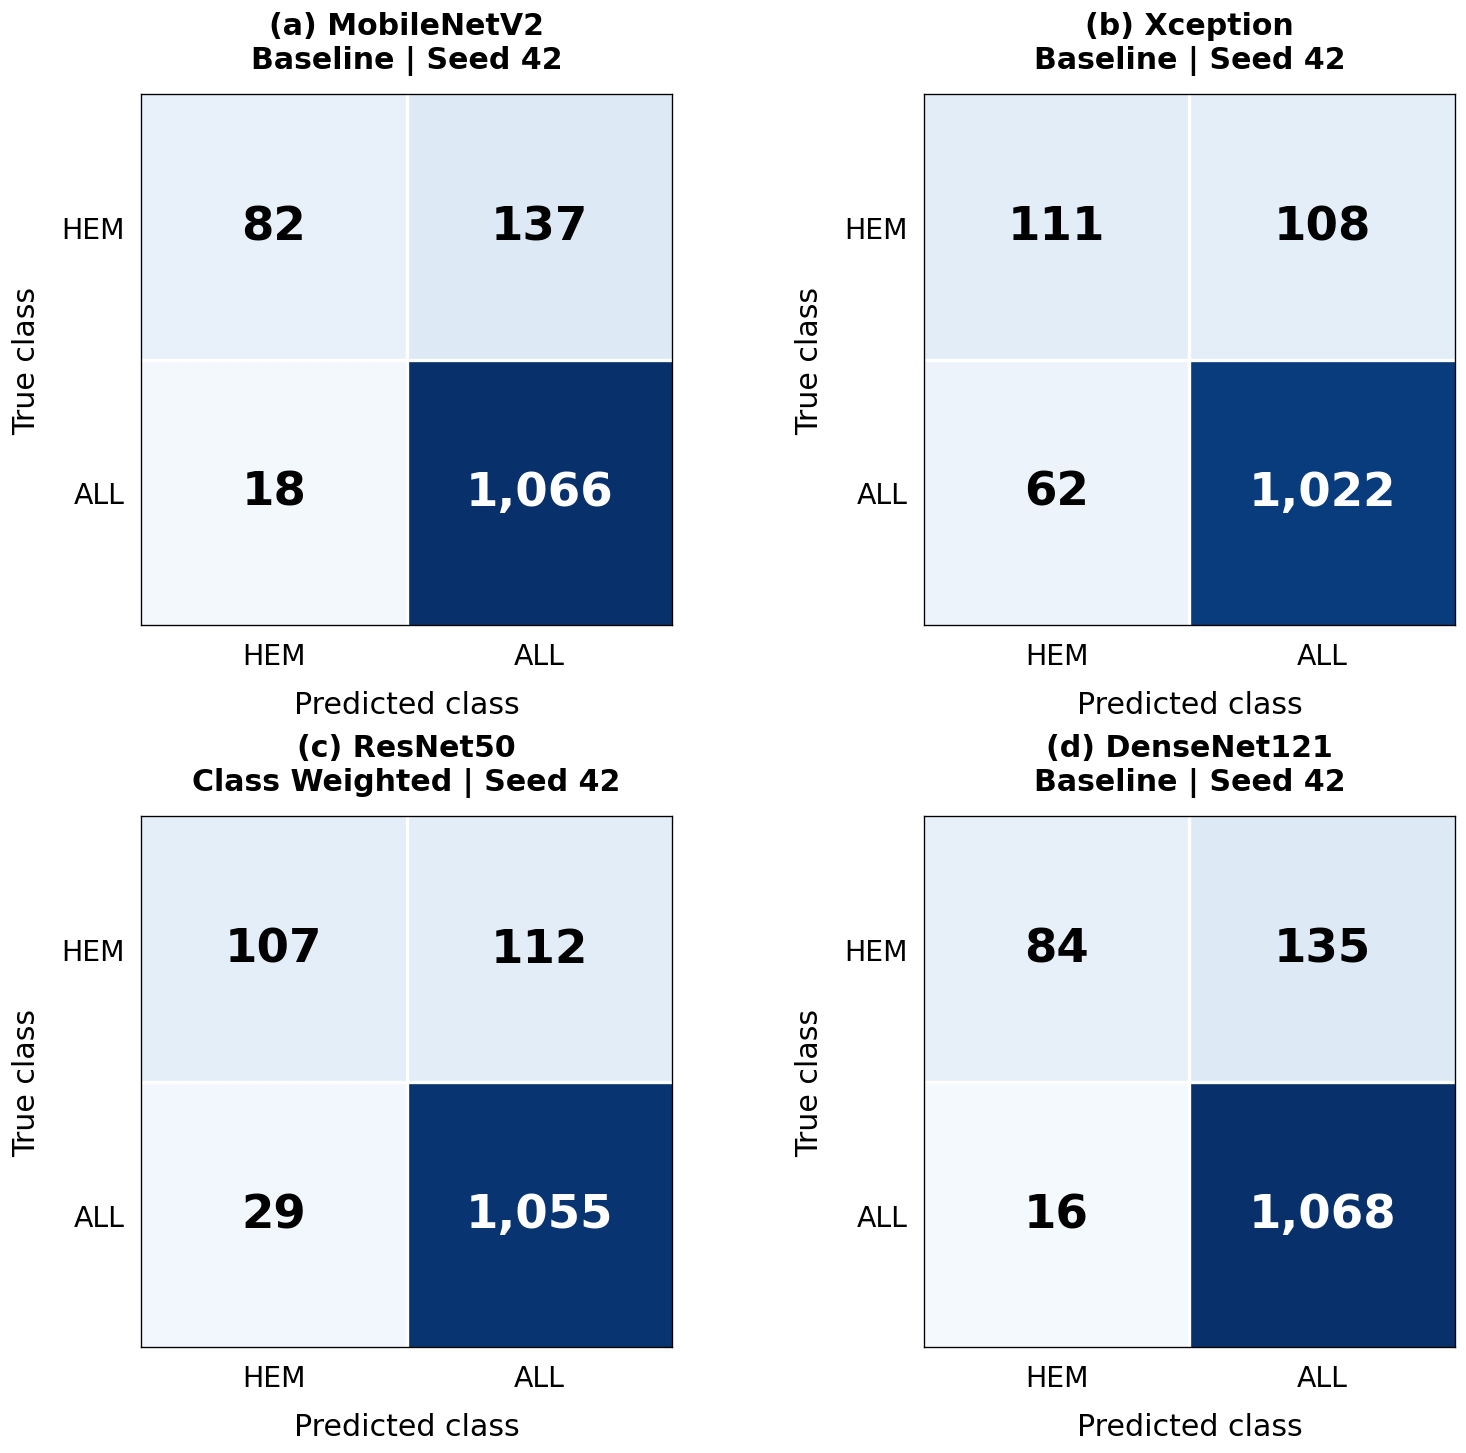

Saved 24 individual figures and one four-panel figure.
Formats: PNG at 300 dpi, vector PDF, and counts as CSV.
Folder: /content/drive/MyDrive/leukemia_SR_revision_v1/validation_confusion_matrices_publication


In [19]:
# Publication-quality VALIDATION confusion matrices.
# Uses saved predictions; no retraining or test-set evaluation.
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from matplotlib.colors import Normalize

root = Path(RUN_ROOT)
out = root / "validation_confusion_matrices_publication"
out.mkdir(parents=True, exist_ok=True)

models = ["MobileNetV2", "Xception", "ResNet50", "DenseNet121"]
class_names = ["HEM", "ALL"]

with open(root / "ensemble_protocol.json") as f:
    protocol = json.load(f)

def load_matrix(path):
    df = pd.read_csv(path)
    assert {"label", "prediction"}.issubset(df.columns), str(path)
    assert df["label"].isin([0, 1]).all()
    assert df["prediction"].isin([0, 1]).all()
    return confusion_matrix(
        df["label"], df["prediction"], labels=[0, 1]
    )

def draw_matrix(ax, cm, title, norm):
    ax.imshow(cm, cmap="Blues", norm=norm, interpolation="nearest")

    ax.set_xticks([0, 1], labels=class_names)
    ax.set_yticks([0, 1], labels=class_names)
    ax.tick_params(axis="both", labelsize=17, length=0, pad=10)
    ax.set_xlabel("Predicted class", fontsize=18, labelpad=12)
    ax.set_ylabel("True class", fontsize=18, labelpad=12)
    ax.set_title(title, fontsize=18, fontweight="bold", pad=16)

    # Large counts with contrast-aware lettering.
    for i in range(2):
        for j in range(2):
            rgba = plt.get_cmap("Blues")(norm(cm[i, j]))
            luminance = (
                0.2126 * rgba[0]
                + 0.7152 * rgba[1]
                + 0.0722 * rgba[2]
            )
            ax.text(
                j, i, f"{cm[i, j]:,}",
                ha="center", va="center",
                fontsize=28, fontweight="bold",
                color="white" if luminance < 0.5 else "black"
            )

    # Clear cell boundaries.
    ax.set_xticks([0.5], minor=True)
    ax.set_yticks([0.5], minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", bottom=False, left=False)

def save_figure(fig, name):
    fig.savefig(
        out / f"{name}.png",
        dpi=300, bbox_inches="tight",
        pad_inches=0.15, facecolor="white"
    )
    fig.savefig(
        out / f"{name}.pdf",
        bbox_inches="tight",
        pad_inches=0.15, facecolor="white"
    )

files = sorted(
    (root / "tasks" / "main").rglob("validation_predictions.csv")
)
assert files, "No saved main-run validation predictions found."

# Consistent colour scale across all 24 runs.
matrices = {path: load_matrix(path) for path in files}
norm = Normalize(
    vmin=0, vmax=max(int(cm.max()) for cm in matrices.values())
)

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.dpi": 120,
    "savefig.dpi": 300
}):
    # Individual figures for all runs.
    for path, cm in matrices.items():
        model, strategy, seed = path.parent.relative_to(
            root / "tasks" / "main"
        ).parts
        strategy_title = strategy.replace("_", " ").title()
        name = f"{model}_{strategy}_{seed}"

        pd.DataFrame(
            cm,
            index=["True_HEM", "True_ALL"],
            columns=["Predicted_HEM", "Predicted_ALL"]
        ).to_csv(out / f"{name}.csv")

        fig, ax = plt.subplots(figsize=(6.5, 6.5),
                               layout="constrained")
        draw_matrix(
            ax, cm,
            f"{model}\n{strategy_title} | {seed.replace('seed', 'Seed ')}",
            norm
        )
        save_figure(fig, name)
        plt.close(fig)

    # Four-panel figure using validation-selected strategies.
    seed = protocol["seed"]
    fig, axes = plt.subplots(
        2, 2, figsize=(13, 12), layout="constrained"
    )

    for letter, model, ax in zip("abcd", models, axes.flat):
        strategy = protocol["arms"][model]
        path = (
            root / "tasks" / "main" / model / strategy
            / f"seed{seed}" / "validation_predictions.csv"
        )
        cm = load_matrix(path)
        draw_matrix(
            ax, cm,
            f"({letter}) {model}\n"
            f"{strategy.replace('_', ' ').title()} | Seed {seed}",
            norm
        )

    save_figure(fig, "selected_models_validation")
    plt.show()

print(f"Saved {len(files)} individual figures and one four-panel figure.")
print("Formats: PNG at 300 dpi, vector PDF, and counts as CSV.")
print(f"Folder: {out}")

## Optional analyses before final-test lock

**Learning curves:** needed only if retaining a data-efficiency claim. This controlled comparison varies the number of TRAINING PATIENTS while keeping the validation patients, maximum epoch budget and selected per-architecture configuration fixed. It compares Xception/DenseNet121 in both baseline and class-weighted arms, at 40%, 70% and 100% of training patients, repeated with two patient-subset seeds. Nested patient subsets are used. It reports patient/image counts, validation metrics and stopping durations. It does not establish intrinsic architectural superiority.

**5×2cv:** an optional complementary analysis on DEVELOPMENT PATIENTS only. It deliberately excludes the locked test analysis groups and reports its actual size. It compares the validation-selected Xception/DenseNet121 procedures; hyperparameters were selected using development labels, so this analysis is a sensitivity analysis, **not an independent confirmatory test**. The primary confirmatory uncertainty is patient-clustered on the untouched test set. Do not claim the repeated halves are independent or that this proves data efficiency.


In [ ]:
# 9. Optional controlled learning curves (24 tasks with default fractions/seeds/arms).
NEW_TASKS=0
LC=[]
if RUN_LEARNING_CURVES:
    pt=TRAIN[['patient_id','label']].drop_duplicates().sort_values('patient_id')
    for subset_seed in [71,113]:
        rng=np.random.default_rng(subset_seed)
        order={c:rng.permutation(pt[pt.label==c].patient_id.to_numpy()).tolist() for c in [0,1]}
        for fraction in LEARNING_FRACTIONS:
            ids=sum([order[c][:max(2,int(np.ceil(fraction*len(order[c]))))] for c in [0,1]],[])
            tr=TRAIN[TRAIN.patient_id.isin(ids)].copy()
            for name in ['Xception','DenseNet121']:
                for arm in STRATEGIES:
                    key=f'learning_curve/{name}/{arm}/subset{subset_seed}/fraction{fraction}'
                    r=run_task(key,name,tr,VAL,SELECTED[name+'__'+arm],arm,SEEDS[0])
                    LC.append({'model':name,'strategy':arm,'fraction':fraction,'subset_seed':subset_seed,
                        'training_patients':tr.patient_id.nunique(),'training_images':len(tr),
                        'best_epoch':r['best_epoch'],'stopping_epoch':r['stopping_epoch'],**r['validation_metrics']})
    atomic_csv(RUN_ROOT/'learning_curves.csv',pd.DataFrame(LC))
else: print('Learning curves disabled: remove data-efficiency claims unless this analysis is completed.')


In [ ]:
# 10. Optional patient-grouped 5x2 development-only sensitivity analysis.
NEW_TASKS=0
CV=[]
if RUN_5X2CV:
    for rep in range(1,6):
        s1,s2=patient_split(DEV,.5,100+rep)
        for direction,(pool,held) in enumerate([(s1,s2),(s2,s1)]):
            tr,va=patient_split(pool,.15,1000+rep)
            assert_disjoint(tr,va,held,TEST)
            atomic_json(RUN_ROOT/f'splits/cv_rep{rep}_direction{direction}.json',{
                'train':sorted(tr.patient_id.unique()),'validation':sorted(va.patient_id.unique()),
                'evaluation':sorted(held.patient_id.unique()),'n_development_images':len(DEV)})
            for name in ['Xception','DenseNet121']:
                key=f'cv/{name}/rep{rep}_direction{direction}'
                r=run_task(key,name,tr,va,SELECTED[name+'__'+ARM[name]],ARM[name],SEEDS[0])
                dest=task_folder(key)/'evaluation_predictions.csv'
                if dest.exists(): pred=load_pred(dest)
                else:
                    m=tf.keras.models.load_model(r['best_model']);pred=prediction_frame(m,held);atomic_csv(dest,pred)
                    del m;tf.keras.backend.clear_session();gc.collect()
                CV.append({'rep':rep,'direction':direction,'model':name,'best_epoch':r['best_epoch'],
                    'stopping_epoch':r['stopping_epoch'],**metrics(pred)})
    cv=pd.DataFrame(CV);atomic_csv(RUN_ROOT/'cv5x2/per_run_metrics.csv',cv)
    tab=cv.pivot(index=['rep','direction'],columns='model',values='accuracy')
    differences=(tab.Xception-tab.DenseNet121).to_numpy().reshape(5,2)
    variance=((differences-differences.mean(axis=1,keepdims=True))**2).sum(axis=1)
    den=np.sqrt(variance.mean());numerator=differences[0,0]
    if den==0: stat=None;p=None;note='Zero estimated variance; test undefined.'
    else: stat=float(numerator/den);p=float(2*student_t.sf(abs(stat),5));note='Development-selected protocol; sensitivity analysis only.'
    atomic_json(RUN_ROOT/'cv5x2/test.json',{'t':stat,'df':5,'p':p,'differences':differences.tolist(),
        'n_development_images':len(DEV),'n_development_patients':DEV.patient_id.nunique(),'note':note})
else: print('5x2 sensitivity analysis disabled; it is not needed to retain the corrected primary comparison.')


In [ ]:
# 11. Inspect convergence BEFORE final testing. Save plots and the review checklist.
hist_rows=[]
for p in sorted((RUN_ROOT/'tasks').rglob('completed.json')):
    r=read_json(p);hist=pd.read_csv(p.parent/'history.csv')
    hist_rows.append({k:r[k] for k in ['key','model','strategy','seed','best_epoch','stopping_epoch','hit_epoch_cap']})
    fig,ax=plt.subplots(figsize=(7,4))
    ax.plot(hist.epoch,hist.loss,label='Training');ax.plot(hist.epoch,hist.val_loss,label='Validation')
    ax.axvline(r['best_epoch'],color='black',linestyle='--',label='Selected checkpoint')
    ax.set(xlabel='Completed epoch',ylabel='Smoothed cross-entropy',title=r['key']);ax.legend();fig.tight_layout()
    fig.savefig(p.parent/'learning_curve.png',dpi=180);plt.close(fig)
hist_summary=pd.DataFrame(hist_rows);atomic_csv(RUN_ROOT/'training_audit.csv',hist_summary)
display(hist_summary)
if hist_summary.hit_epoch_cap.any():
    print('ATTENTION: epoch-cap runs exist. Inspect their curves before final testing. Do not describe all runs as converged.')
print('Also inspect splits/partition_counts.csv, tuning_summary.csv and main_validation_summary.csv.')
# No automatic final-test execution: the next cell intentionally requires a readiness flag.


## Final test — run only after all development decisions are frozen

Set the flag below to True after inspecting development diagnostics. This creates an immutable final-test lock and evaluates **all prespecified primary arms and seeds**, all three ensembles, and a validation-selected reference model. It does not select the best ensemble or reference from test scores. A resumed final evaluation reuses saved predictions and repeats deterministic statistics.

Bootstrap confidence intervals resample whole analysis groups within class. Each group contains one original patient ID or all IDs connected through identical images. This conservatively accounts for uncertain provenance; it does not assert shared biological identity. All cells belonging to a sampled analysis group are retained together. Paired differences use identical bootstrap samples. The permutation test flips the model labels for **whole patient clusters** (including all their cells), testing cell-accuracy differences under a analysis-group-level exchangeability assumption. Holm adjustment covers every prespecified reference comparison. Confidence intervals and p-values do not correct acquisition bias or replace external validation. Few test analysis groups can produce wide or unstable intervals; report the actual patient counts.


In [ ]:
# 12. Cluster-aware evaluation functions (no model training).
CI_KEYS=['accuracy','balanced_accuracy','macro_f1','sensitivity_all','specificity_hem','roc_auc','patient_mean_cell_accuracy']

def aligned(a,b):
    a=a.sort_values('relative_path').reset_index(drop=True);b=b.sort_values('relative_path').reset_index(drop=True)
    assert a.relative_path.equals(b.relative_path)
    assert np.array_equal(a.label,b.label) and np.array_equal(a.patient_id,b.patient_id)
    return a,b

def bootstrap_indices(pred,n=BOOTSTRAPS,seed=42):
    rng=np.random.default_rng(seed)
    groups={g:np.flatnonzero(pred.patient_id.to_numpy()==g) for g in pred.patient_id.unique()}
    strata={c:pred.loc[pred.label==c,'patient_id'].unique() for c in [0,1]}
    for _ in range(n):
        ids=np.concatenate([rng.choice(strata[c],size=len(strata[c]),replace=True) for c in [0,1]])
        # Rename repeated bootstrap patients so patient_mean_cell_accuracy respects multiplicity.
        chunks=[]
        for j,g in enumerate(ids):
            chunk=pred.iloc[groups[g]].copy();chunk['patient_id']=str(j);chunks.append(chunk)
        yield pd.concat(chunks,ignore_index=True),np.concatenate([groups[g] for g in ids])

def cluster_ci(pred):
    values={k:[] for k in CI_KEYS}
    for sampled,_ in bootstrap_indices(pred):
        m=metrics(sampled)
        for k in CI_KEYS: values[k].append(m[k])
    return {k:{'estimate':metrics(pred)[k],'low':float(np.quantile(v,.025)),
               'high':float(np.quantile(v,.975))} for k,v in values.items()}

def paired_cluster(a,b):
    a,b=aligned(a,b);diffs={k:[] for k in CI_KEYS}
    for sampled,idx in bootstrap_indices(a):
        other=b.iloc[idx].copy().reset_index(drop=True);other['patient_id']=sampled.patient_id
        ma,mb=metrics(sampled),metrics(other)
        for k in CI_KEYS: diffs[k].append(ma[k]-mb[k])
    # Cluster-wise exchangeability/sign-flip test of cell-accuracy difference.
    delta=(a.prediction.to_numpy()==a.label.to_numpy()).astype(int)-(b.prediction.to_numpy()==b.label.to_numpy()).astype(int)
    sums=pd.DataFrame({'g':a.patient_id,'d':delta}).groupby('g').d.sum().to_numpy()
    observed=abs(sums.sum());rng=np.random.default_rng(2026);extreme=0
    for start in range(0,PERMUTATIONS,1000):
        n=min(1000,PERMUTATIONS-start)
        sims=np.abs((rng.choice([-1,1],size=(n,len(sums)))*sums).sum(axis=1))
        extreme+=int((sims>=observed).sum())
    return {'difference_a_minus_b':{k:{'estimate':metrics(a)[k]-metrics(b)[k],
       'low':float(np.quantile(v,.025)),'high':float(np.quantile(v,.975))} for k,v in diffs.items()},
       'cluster_permutation_p':float((extreme+1)/(PERMUTATIONS+1))}

def holm(ps):
    order=np.argsort(ps);out=np.zeros(len(ps));last=0.
    for rank,i in enumerate(order):
        last=max(last,min(1.,(len(ps)-rank)*ps[i]));out[i]=last
    return out.tolist()

def save_eval(name,pred,root):
    root.mkdir(parents=True,exist_ok=True);atomic_csv(root/(name+'_predictions.csv'),pred)
    m=metrics(pred);atomic_json(root/(name+'_metrics.json'),m)
    cm=np.array([[m['tn'],m['fp']],[m['fn'],m['tp']]])
    fig,ax=plt.subplots(figsize=(4,4));ax.imshow(cm,cmap='Blues')
    for (i,j),v in np.ndenumerate(cm): ax.text(j,i,str(v),ha='center',va='center')
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['HEM','ALL'],yticklabels=['HEM','ALL'],
           xlabel='Predicted',ylabel='True',title=name);fig.tight_layout();fig.savefig(root/(name+'_confusion.png'),dpi=220);plt.close(fig)
    fpr,tpr,thresholds=roc_curve(pred.label,pred.p_all)
    atomic_csv(root/(name+'_roc.csv'),pd.DataFrame({'fpr':fpr,'tpr':tpr,'threshold':thresholds}))
    return m


In [22]:
# 13. FINAL TEST. Explicitly freeze protocol after reviewing development diagnostics.
READY_FOR_FINAL_TEST = True  # change to True when ready; rerunning this cell is safe
assert READY_FOR_FINAL_TEST, 'Inspect development results, then set READY_FOR_FINAL_TEST=True.'
expected_main=len(MODELS)*len(STRATEGIES)*len(SEEDS)
main_paths=list((RUN_ROOT/'tasks/main').rglob('completed.json'))
assert len(main_paths)==expected_main,'Finish all primary training tasks first.'
assert (RUN_ROOT/'ensemble/meta.json').exists(),'Finish OOF ensemble fitting first.'
if RUN_LEARNING_CURVES: assert (RUN_ROOT/'learning_curves.csv').exists()
if RUN_5X2CV: assert (RUN_ROOT/'cv5x2/test.json').exists()
lock={'protocol_hash':CONFIG_HASH,'ensemble_protocol':read_json(RUN_ROOT/'ensemble_protocol.json'),
      'selected_configs':read_json(RUN_ROOT/'selected_configs.json'),
      'optional_learning_curves':RUN_LEARNING_CURVES,'optional_5x2':RUN_5X2CV}
lockpath=RUN_ROOT/'FINAL_TEST_LOCK.json'
if lockpath.exists(): assert read_json(lockpath)['lock_hash']==digest(lock),'Protocol differs from frozen test protocol.'
else: atomic_json(lockpath,{'lock_hash':digest(lock),'spec':lock,'time':now()})
FINAL=RUN_ROOT/'final_test';FINAL.mkdir(exist_ok=True)
PREDS={};records=[];EP=read_json(RUN_ROOT/'ensemble_protocol.json')
for path in sorted(main_paths):
    r=read_json(path);name=f"{r['model']}__{r['strategy']}__seed{r['seed']}"
    dest=FINAL/(name+'_predictions.csv')
    if dest.exists(): pred=load_pred(dest)
    else:
        m=tf.keras.models.load_model(r['best_model']);pred=prediction_frame(m,TEST);atomic_csv(dest,pred)
        # Inference timing: repeated warmed-up device forward pass, batch=1, excludes disk/decode.
        sample=next(iter(dataset(TEST.head(1))))[0]
        for _ in range(10): m(sample,training=False).numpy()
        times=[]
        for _ in range(100):
            t0=time.perf_counter();m(sample,training=False).numpy();times.append((time.perf_counter()-t0)*1000)
        atomic_json(FINAL/(name+'_compute.json'),{'parameters':m.count_params(),
            'checkpoint_bytes_includes_optimizer':Path(r['best_model']).stat().st_size,
            'batch1_median_ms':float(np.median(times)),'batch1_p95_ms':float(np.quantile(times,.95)),
            'device':str(tf.config.list_physical_devices('GPU')),'tensorflow':tf.__version__,
            'scope':'warmed-up batch1 forward pass; excludes preprocessing and disk I/O; no mobile-device claim'})
        del m;tf.keras.backend.clear_session();gc.collect()
    PREDS[name]=pred
    records.append({'name':name,'model':r['model'],'strategy':r['strategy'],'seed':r['seed'],**save_eval(name,pred,FINAL)})
base_names=[f"{n}__{EP['arms'][n]}__seed{SEEDS[0]}" for n in MODELS]
base=[PREDS[n].sort_values('relative_path').reset_index(drop=True) for n in base_names]
for b in base[1:]: aligned(base[0],b)
X=np.column_stack([p.p_all for p in base]);e=read_json(RUN_ROOT/'ensemble/meta.json')
logits=X@np.asarray(e['coef'])[0]+e['intercept'][0]
ensemble_probs={'SoftVote':X.mean(axis=1),'WeightedVote':X@np.asarray(e['weights']),
                'Stacked':1/(1+np.exp(-np.clip(logits,-700,700)))}
for name,p in ensemble_probs.items():
    pred=base[0].copy();pred['p_all']=p;pred['prediction']=(p>=.5).astype(int);PREDS[name]=pred
    records.append({'name':name,'model':name,'strategy':'ensemble','seed':SEEDS[0],**save_eval(name,pred,FINAL)})
atomic_csv(FINAL/'all_metrics.csv',pd.DataFrame(records))
# Within-test patient CIs: prespecified seed, both imbalance arms + all ensembles.
for name,pred in PREDS.items():
    if 'seed' not in name or name.endswith('seed'+str(SEEDS[0])):
        dest=FINAL/(name+'_patient_bootstrap_ci.json')
        if not dest.exists(): atomic_json(dest,cluster_ci(pred))
# Prespecified comparisons: 6 architecture pairs for selected arms, 4 imbalance comparisons,
# and all three ensembles versus the VALIDATION-selected reference. One Holm family (13).
comparisons=list(itertools.combinations(base_names,2))
comparisons += [(f'{n}__class_weighted__seed{SEEDS[0]}',f'{n}__baseline__seed{SEEDS[0]}') for n in MODELS]
reference=f"{EP['reference_model']}__{EP['arms'][EP['reference_model']]}__seed{SEEDS[0]}"
comparisons += [(n,reference) for n in ensemble_probs]
paired=[]
for a,b in comparisons:
    key=a+'__vs__'+b;dest=FINAL/(key+'_paired.json')
    r=read_json(dest) if dest.exists() else paired_cluster(PREDS[a],PREDS[b])
    atomic_json(dest,r);paired.append({'a':a,'b':b,**r})
adjusted=holm([r['cluster_permutation_p'] for r in paired])
for r,p in zip(paired,adjusted): r['holm_adjusted_p']=p
atomic_json(FINAL/'paired_comparisons.json',paired)
primary=pd.DataFrame(records);primary=primary[primary.strategy!='ensemble']
seed_summary=primary.groupby(['model','strategy'])[['accuracy','macro_f1','balanced_accuracy','roc_auc']].agg(['mean','std'])
seed_summary.to_csv(FINAL/'across_seed_summary.csv')  # std is variability across seeds, NOT a CI
print('Final evaluation complete. No model is selected using these test scores.')
display(pd.DataFrame(records)[['name','accuracy','macro_f1','sensitivity_all','specificity_hem','roc_auc']])


Final evaluation complete. No model is selected using these test scores.


,name,accuracy,macro_f1,sensitivity_all,specificity_hem,roc_auc
0,DenseNet121__baseline__seed123,0.871729,0.837883,0.982075,0.641026,0.934318
1,DenseNet121__baseline__seed2026,0.875558,0.844089,0.979245,0.658777,0.926841
2,DenseNet121__baseline__seed42,0.857052,0.813835,0.989623,0.579882,0.934342
3,DenseNet121__class_weighted__seed123,0.887683,0.862095,0.974528,0.706114,0.933300
4,DenseNet121__class_weighted__seed2026,0.876835,0.848260,0.968868,0.684418,0.934472
5,DenseNet121__class_weighted__seed42,0.889598,0.863043,0.983019,0.694280,0.930094
6,MobileNetV2__baseline__seed123,0.851946,0.806565,0.987736,0.568047,0.935914
7,MobileNetV2__baseline__seed2026,0.873006,0.840662,0.978302,0.652860,0.922204
8,MobileNetV2__baseline__seed42,0.856414,0.814334,0.984906,0.587771,0.928422
9,MobileNetV2__class_weighted__seed123,0.864710,0.828376,0.979245,0.625247,0.931175


## External validation (Reviewer 2 Q5)

A compatible independent dataset is **not bundled or invented**. Provide a CSV with columns `path,label,patient_id,source,site,stain,microscope`; `label` must be 1 for ALL blast cells and 0 for normal cells. Paths must exist in Colab/Drive. Include only eligible presegmented single-cell images with known labels and patient IDs. A dataset of unsegmented smears, AML, mixed unspecified leukemias, or synthetic cells is not interchangeable with this task. Verify acquisition provenance and independence before setting the confirmation flag. Different manufacturer/stain robustness can only be claimed when those differences are documented.

This cell applies the frozen models and ensemble without tuning. It audits exact pixel overlap, saves external predictions, confusion matrices, patient CIs and paired comparisons, and exports architecture rankings for comparison with internal results. Pixel hashing cannot prove cohort independence; provenance review is still required. If no external data are supplied, the coverage report marks Q5 unaddressed experimentally.


In [20]:
# 14. Optional independent external evaluation; may also be resumed.
EXTERNAL=RUN_ROOT/'external';EXTERNAL.mkdir(exist_ok=True)
if not EXTERNAL_MANIFEST_CSV:
    atomic_json(EXTERNAL/'status.json',{'completed':False,'reason':'No compatible independent external dataset supplied.'})
    print('External validation NOT performed. Reviewer 2 Q5 remains a limitation.')
else:
    assert (RUN_ROOT/'FINAL_TEST_LOCK.json').exists(),'Freeze development and run internal final evaluation first.'
    assert EXTERNAL_PROVENANCE_CONFIRMED,'Verify external eligibility, patient provenance and acquisition metadata first.'
    ext=pd.read_csv(EXTERNAL_MANIFEST_CSV,dtype={'patient_id':str})
    needed={'path','label','patient_id','source','site','stain','microscope'}
    assert needed.issubset(ext.columns),f'External CSV requires {needed}'
    assert ext[list(needed)].notna().all().all() and ext[list(needed)].astype(str).apply(lambda x:x.str.strip().ne('')).all().all()
    assert set(ext.label)=={0,1} and not ext.path.duplicated().any()
    assert ext.groupby(['source','patient_id']).label.nunique().max()==1
    ext['relative_path']=ext.path.astype(str)
    ext['patient_id']=ext.source.astype(str)+'::'+ext.patient_id.astype(str)
    ext['sha256_pixels']=[pixel_hash(p)[0] for p in ext.path]
    assert not ext.sha256_pixels.duplicated().any(),'Resolve duplicates in external data before evaluation.'
    assert set(ext.sha256_pixels).isdisjoint(manifest.sha256_pixels),'External/internal exact image overlap.'
    ehash=digest(ext.to_dict('records'));f=EXTERNAL/'manifest_lock.json'
    if f.exists(): assert read_json(f)['hash']==ehash,'External manifest changed. Use a new external evaluation folder/protocol.'
    else: atomic_json(f,{'hash':ehash,'time':now()})
    atomic_csv(EXTERNAL/'manifest.csv',ext)
    preds={};ext_records=[];EP=read_json(RUN_ROOT/'ensemble_protocol.json')
    for name in MODELS:
        task=task_folder(f"main/{name}/{EP['arms'][name]}/seed{SEEDS[0]}")
        r=read_json(task/'completed.json');dest=EXTERNAL/(name+'_predictions.csv')
        if dest.exists(): p=load_pred(dest)
        else:
            m=tf.keras.models.load_model(r['best_model']);p=prediction_frame(m,ext);atomic_csv(dest,p)
            del m;tf.keras.backend.clear_session();gc.collect()
        preds[name]=p.sort_values('relative_path').reset_index(drop=True)
    X=np.column_stack([preds[n].p_all for n in MODELS]);e=read_json(RUN_ROOT/'ensemble/meta.json')
    logits=X@np.asarray(e['coef'])[0]+e['intercept'][0]
    for name,p in {'SoftVote':X.mean(1),'WeightedVote':X@np.array(e['weights']),
                   'Stacked':1/(1+np.exp(-np.clip(logits,-700,700)))}.items():
        z=preds[MODELS[0]].copy();z['p_all']=p;z['prediction']=(p>=.5).astype(int);preds[name]=z
    for name,p in preds.items():
        ext_records.append({'name':name,**save_eval(name,p,EXTERNAL)})
        ci=EXTERNAL/(name+'_patient_bootstrap_ci.json')
        if not ci.exists(): atomic_json(ci,cluster_ci(p))
    atomic_csv(EXTERNAL/'metrics_and_rankings.csv',pd.DataFrame(ext_records).sort_values('balanced_accuracy',ascending=False))
    pairs=[]
    for a,b in list(itertools.combinations(MODELS,2))+[(n,EP['reference_model']) for n in ['SoftVote','WeightedVote','Stacked']]:
        dest=EXTERNAL/(a+'__vs__'+b+'_paired.json')
        r=read_json(dest) if dest.exists() else paired_cluster(preds[a],preds[b]);atomic_json(dest,r)
        pairs.append({'a':a,'b':b,**r})
    for r,p in zip(pairs,holm([r['cluster_permutation_p'] for r in pairs])):r['holm_adjusted_p']=p
    atomic_json(EXTERNAL/'paired_comparisons.json',pairs)
    atomic_json(EXTERNAL/'status.json',{'completed':True,'manifest_hash':ehash,'n_patients':ext.patient_id.nunique(),
        'n_images':len(ext),'acquisition_metadata':ext[['source','site','stain','microscope']].drop_duplicates().to_dict('records')})
    print('External evaluation complete. Inspect documented acquisition differences before making robustness claims.')


External validation NOT performed. Reviewer 2 Q5 remains a limitation.


In [23]:
# 15. Reviewer coverage and compact export (checkpoints remain on Drive).
# Summary figures are generated from saved predictions only.
if (RUN_ROOT/'final_test/all_metrics.csv').exists():
    ep=read_json(RUN_ROOT/'ensemble_protocol.json');root=RUN_ROOT/'final_test'
    plot_names=[f"{m}__{ep['arms'][m]}__seed{SEEDS[0]}" for m in MODELS]+['SoftVote','WeightedVote','Stacked']
    fig,ax=plt.subplots(figsize=(7,6))
    for name in plot_names:
        p=load_pred(root/(name+'_predictions.csv'));fpr,tpr,_=roc_curve(p.label,p.p_all)
        ax.plot(fpr,tpr,label=f'{name.split("__")[0]} (AUC {roc_auc_score(p.label,p.p_all):.3f})')
    ax.plot([0,1],[0,1],'k--');ax.set(xlabel='False-positive rate',ylabel='ALL sensitivity',title='Patient-disjoint internal test');ax.legend(fontsize=8)
    fig.tight_layout();fig.savefig(root/'combined_roc.png',dpi=300);plt.close(fig)
    table=pd.read_csv(root/'all_metrics.csv').set_index('name').loc[plot_names]
    fig,ax=plt.subplots(figsize=(10,5));x=np.arange(len(table));w=.25
    for j,metric in enumerate(['accuracy','balanced_accuracy','macro_f1']):ax.bar(x+(j-1)*w,table[metric],width=w,label=metric)
    ax.set(xticks=x,xticklabels=[n.split('__')[0] for n in plot_names],ylim=(0,1),ylabel='Score',title='Prespecified models and ensembles')
    ax.tick_params(axis='x',rotation=30);ax.legend();fig.tight_layout();fig.savefig(root/'model_ensemble_comparison.png',dpi=300);plt.close(fig)
coverage=[
 {'reviewer':'R1.1','concern':'Patient independence','evidence':'audit/manifest.csv; splits/primary_manifest.csv; final_test/*patient_bootstrap_ci.json',
  'status':'completed' if (RUN_ROOT/'final_test/all_metrics.csv').exists() else 'pending'},
 {'reviewer':'R1.2 / R2.Q1','concern':'Complete comparable training','evidence':'training_audit.csv; tasks/**/history.csv; learning_curve.png',
  'status':'inspect convergence/cap flags before claiming completion'},
 {'reviewer':'R1.3 / R2.Q2','concern':'Leakage-free ensemble on complete eligible cohort','evidence':'ensemble/oof_probabilities.csv; meta.json; final_test/paired_comparisons.json',
  'status':'completed' if (RUN_ROOT/'final_test/paired_comparisons.json').exists() else 'pending'},
 {'reviewer':'R1.4','concern':'Metrics, predictions, checkpoint and stopping epoch','evidence':'tasks/**/validation_predictions.csv; completed.json; final_test/*predictions.csv; *_metrics.json',
  'status':'new results exported; explain old fold-0/80:20 experiment separately'},
 {'reviewer':'R1.5','concern':'Interpretation and clinical scope','evidence':'Manual manuscript revision required',
  'status':'restrict to presegmented cell classification; no clinical deployment claim'},
 {'reviewer':'R2.Q3','concern':'DenseNet hyperparameters','evidence':'tuning_summary.csv; main_validation_summary.csv; training_audit.csv',
  'status':'completed' if (RUN_ROOT/'main_validation_summary.csv').exists() else 'pending'},
 {'reviewer':'R2.Q4','concern':'Class bias','evidence':'final_test/all_metrics.csv; paired_comparisons.json; across_seed_summary.csv',
  'status':'completed' if (RUN_ROOT/'final_test/paired_comparisons.json').exists() else 'pending'},
 {'reviewer':'R2.Q5','concern':'Independent acquisition robustness','evidence':'external/status.json; metrics_and_rankings.csv',
  'status':'completed' if (EXTERNAL/'status.json').exists() and read_json(EXTERNAL/'status.json')['completed'] else 'UNANSWERED experimentally; external data required'},
 {'reviewer':'Data efficiency','concern':'Training-size claim','evidence':'learning_curves.csv',
  'status':'controlled analysis exported; interpret cautiously' if (RUN_ROOT/'learning_curves.csv').exists() else 'REMOVE claim unless optional learning curves are completed'},
]
atomic_csv(RUN_ROOT/'reviewer_coverage.csv',pd.DataFrame(coverage));display(pd.DataFrame(coverage))
export=Path('/content/leukemia_SR_revision_results.zip')
with zipfile.ZipFile(export,'w',zipfile.ZIP_DEFLATED) as z:
    for p in RUN_ROOT.rglob('*'):
        if p.is_file() and p.suffix.lower() in {'.json','.csv','.png'} and 'epoch_' not in '/'.join(p.relative_to(RUN_ROOT).parts) and 'checkpoint_smoke_test' not in p.parts:
            z.write(p,p.relative_to(RUN_ROOT).as_posix())
shutil.copy2(export,RUN_ROOT/export.name)
print('All outputs:',RUN_ROOT,'Compact export:',RUN_ROOT/export.name)
# Optional local download:
# from google.colab import files
# files.download(str(export))


,reviewer,concern,evidence,status
0,R1.1,Patient independence,audit/manifest.csv; splits/primary_manifest.cs...,completed
1,R1.2 / R2.Q1,Complete comparable training,training_audit.csv; tasks/**/history.csv; lear...,inspect convergence/cap flags before claiming ...
2,R1.3 / R2.Q2,Leakage-free ensemble on complete eligible cohort,ensemble/oof_probabilities.csv; meta.json; fin...,completed
3,R1.4,"Metrics, predictions, checkpoint and stopping ...",tasks/**/validation_predictions.csv; completed...,new results exported; explain old fold-0/80:20...
4,R1.5,Interpretation and clinical scope,Manual manuscript revision required,restrict to presegmented cell classification; ...
5,R2.Q3,DenseNet hyperparameters,tuning_summary.csv; main_validation_summary.cs...,completed
6,R2.Q4,Class bias,final_test/all_metrics.csv; paired_comparisons...,completed
7,R2.Q5,Independent acquisition robustness,external/status.json; metrics_and_rankings.csv,UNANSWERED experimentally; external data required
8,Data efficiency,Training-size claim,learning_curves.csv,REMOVE claim unless optional learning curves a...


All outputs: /content/drive/MyDrive/leukemia_SR_revision_v1 Compact export: /content/drive/MyDrive/leukemia_SR_revision_v1/leukemia_SR_revision_results.zip


## What to send back after the run

Share `leukemia_SR_revision_results.zip`. It includes the audit, exact partitions, tuning/main histories, individual predictions, ensemble provenance, metrics, uncertainty, paired comparisons, figures and reviewer coverage. It omits large model files; those stay in the Drive task folders.

### Manuscript and response requirements
- Replace every old table and figure that depends on the invalid/incomplete experiments. Explain the old 3,002-image fold-0 cross-validation provenance and corrected class distribution candidly.
- Report actual patients and images per split; state that cells are clustered within patients. No patient-level diagnosis endpoint has been validated by cell-level metrics.
- State frozen-backbone warmup, fine-tuning settings, frozen BN, class weights, validation criteria, best epoch and stopping epoch. Across-seed SD is not a confidence interval.
- Report all three ensemble results whether or not any improves on the single-model reference. A nonsignificant improvement does not establish equivalence or superiority.
- The optional Angelakis et al. AML gene-expression study is background only, never a direct ALL microscopy comparator.
- Remove intrinsic architecture, data-efficiency and clinical deployment claims unless supported by the new evidence. Q5 requires external data or an explicit limitation response; this notebook cannot create that evidence.

### Source documentation
- C-NMC 2019 / TCIA: https://www.cancerimagingarchive.net/collection/c-nmc-2019/ (training cohort: 73 subjects; original folds are subject-separated).
- Keras full-model saving: https://keras.io/guides/serialization_and_saving/ (architecture, weights, compile configuration and optimizer state in `.keras`).
- Runtime versions and exact protocol are recorded by this notebook. Run-time smoke and resume tests should be performed on Colab before the expensive experiment queue.
